In [114]:
import pandas as pd
import numpy as np
from mlxtend.plotting import plot_decision_regions

In [115]:
df = pd.DataFrame()

In [116]:
df['x1'] = [1,2,3,4,5,6,6,7,9,9]
df['x2'] = [5,3,6,8,1,9,5,8,9,2]
df['label'] = [1,1,0,1,0,1,0,1,0,0]

In [117]:
df

,x1,x2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,6,5,0
7,7,8,1
8,9,9,0
9,9,2,0


<Axes: xlabel='x1', ylabel='x2'>

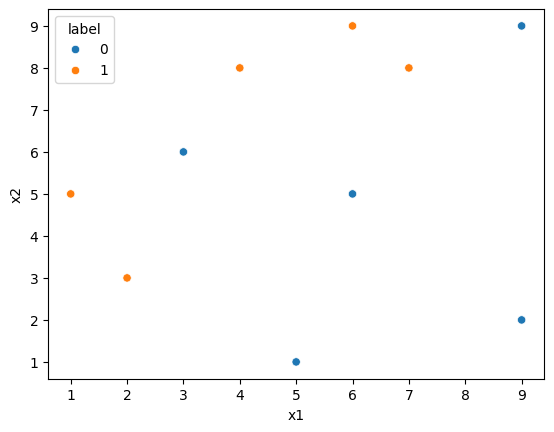

In [118]:
import seaborn as sns
sns.scatterplot(x=df['x1'], y=df['x2'], hue=df['label'])

In [119]:
df['weight'] = 1/df.shape[0]
df

,x1,x2,label,weight
0,1,5,1,0.1
1,2,3,1,0.1
2,3,6,0,0.1
3,4,8,1,0.1
4,5,1,0,0.1
5,6,9,1,0.1
6,6,5,0,0.1
7,7,8,1,0.1
8,9,9,0,0.1
9,9,2,0,0.1


In [120]:
from sklearn.tree import DecisionTreeClassifier
dt1 = DecisionTreeClassifier(max_depth=1)

In [121]:
X = df.iloc[:,:2].values
y = df['label'].values

In [122]:
dt1.fit(X,y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[0] <= 2.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.469\nsamples = 8\nvalue = [5, 3]'),
 Text(0.625, 0.5, '  False')]

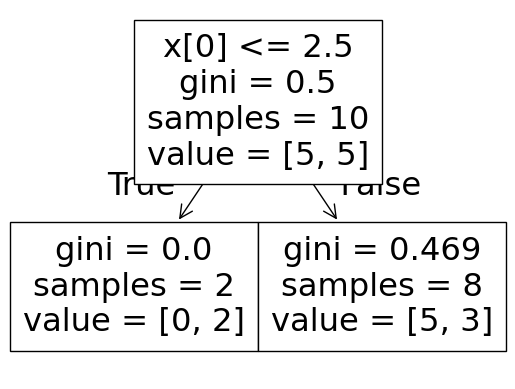

In [123]:
from sklearn.tree import plot_tree
plot_tree(dt1)

<Axes: >

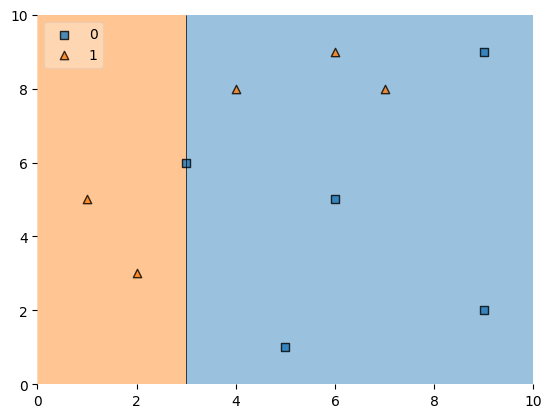

In [124]:
plot_decision_regions(X,y,clf=dt1,legend=2)

In [125]:
df['y_pred'] = dt1.predict(X)
df

,x1,x2,label,weight,y_pred
0,1,5,1,0.1,1
1,2,3,1,0.1,1
2,3,6,0,0.1,0
3,4,8,1,0.1,0
4,5,1,0,0.1,0
5,6,9,1,0.1,0
6,6,5,0,0.1,0
7,7,8,1,0.1,0
8,9,9,0,0.1,0
9,9,2,0,0.1,0


In [126]:
def claculate_model_weight(error):
    return 0.5*np.log((1-error)/(error+0.0000000000001))

In [127]:
alpha = claculate_model_weight(0.3)
alpha1 = alpha

In [128]:
def update_row_weight(row,alpha = alpha):
    if row['label'] == row['y_pred']:
        return row['weight']*np.exp(-alpha)
    else:
        return row['weight']*np.exp(alpha)

In [129]:
df['updated_weight'] = df.apply(update_row_weight,axis=1)
df

,x1,x2,label,weight,y_pred,updated_weight
0,1,5,1,0.1,1,0.065465
1,2,3,1,0.1,1,0.065465
2,3,6,0,0.1,0,0.065465
3,4,8,1,0.1,0,0.152753
4,5,1,0,0.1,0,0.065465
5,6,9,1,0.1,0,0.152753
6,6,5,0,0.1,0,0.065465
7,7,8,1,0.1,0,0.152753
8,9,9,0,0.1,0,0.065465
9,9,2,0,0.1,0,0.065465


In [130]:
df['normalized_weight'] = df['updated_weight']/df['updated_weight'].sum()
df

,x1,x2,label,weight,y_pred,updated_weight,normalized_weight
0,1,5,1,0.1,1,0.065465,0.071429
1,2,3,1,0.1,1,0.065465,0.071429
2,3,6,0,0.1,0,0.065465,0.071429
3,4,8,1,0.1,0,0.152753,0.166667
4,5,1,0,0.1,0,0.065465,0.071429
5,6,9,1,0.1,0,0.152753,0.166667
6,6,5,0,0.1,0,0.065465,0.071429
7,7,8,1,0.1,0,0.152753,0.166667
8,9,9,0,0.1,0,0.065465,0.071429
9,9,2,0,0.1,0,0.065465,0.071429


In [131]:
df['cumsum_upper'] = np.cumsum(df['normalized_weight'])
df['cumsum_lower'] = df['cumsum_upper'] - df['normalized_weight']
df

,x1,x2,label,weight,y_pred,updated_weight,normalized_weight,cumsum_upper,cumsum_lower
0,1,5,1,0.1,1,0.065465,0.071429,0.071429,0.000000
1,2,3,1,0.1,1,0.065465,0.071429,0.142857,0.071429
2,3,6,0,0.1,0,0.065465,0.071429,0.214286,0.142857
3,4,8,1,0.1,0,0.152753,0.166667,0.380952,0.214286
4,5,1,0,0.1,0,0.065465,0.071429,0.452381,0.380952
5,6,9,1,0.1,0,0.152753,0.166667,0.619048,0.452381
6,6,5,0,0.1,0,0.065465,0.071429,0.690476,0.619048
7,7,8,1,0.1,0,0.152753,0.166667,0.857143,0.690476
8,9,9,0,0.1,0,0.065465,0.071429,0.928571,0.857143
9,9,2,0,0.1,0,0.065465,0.071429,1.000000,0.928571


In [132]:
def create_dataset(df):
    indices = []
    for i in range(df.shape[0]):
        a = np.random.random()
        for index,row in df.iterrows():
            if row['cumsum_upper'] > a and a > row['cumsum_lower']:
                indices.append(index)
    return indices


In [133]:
index_values = create_dataset(df)
index_values

[2, 1, 1, 3, 6, 2, 3, 7, 3, 8]

In [134]:
second_df = df.iloc[index_values,[0,1,2,3]]
second_df

,x1,x2,label,weight
2,3,6,0,0.1
1,2,3,1,0.1
1,2,3,1,0.1
3,4,8,1,0.1
6,6,5,0,0.1
2,3,6,0,0.1
3,4,8,1,0.1
7,7,8,1,0.1
3,4,8,1,0.1
8,9,9,0,0.1


In [135]:
import matplotlib.pyplot as plt

[Text(0.5, 0.75, 'x[1] <= 7.0\ngini = 0.48\nsamples = 10\nvalue = [4, 6]'), Text(0.25, 0.25, 'gini = 0.48\nsamples = 5\nvalue = [3, 2]'), Text(0.375, 0.5, 'True  '), Text(0.75, 0.25, 'gini = 0.32\nsamples = 5\nvalue = [1, 4]'), Text(0.625, 0.5, '  False')]
   x1  x2  label  weight  y_pred
2   3   6      0     0.1       0
1   2   3      1     0.1       0
1   2   3      1     0.1       0
3   4   8      1     0.1       1
6   6   5      0     0.1       0
2   3   6      0     0.1       0
3   4   8      1     0.1       1
7   7   8      1     0.1       1
3   4   8      1     0.1       1
8   9   9      0     0.1       1


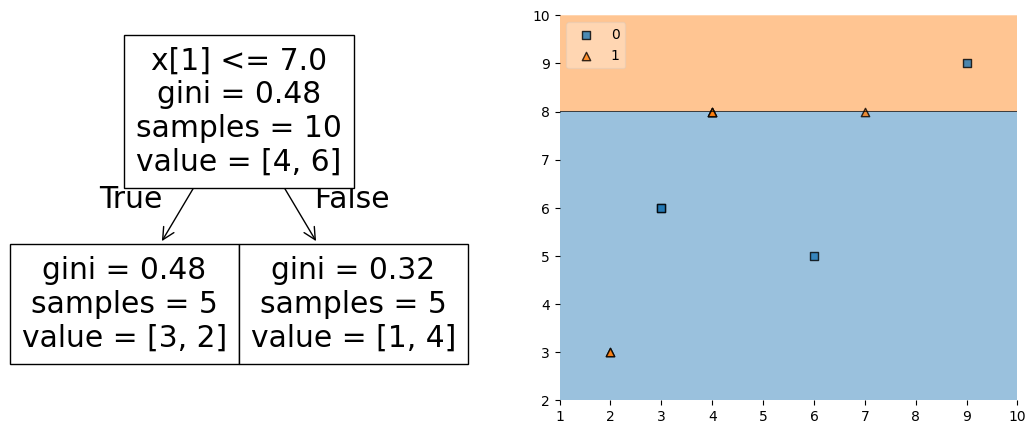

In [136]:
dt2 = DecisionTreeClassifier(max_depth=1)

X = second_df.iloc[:,:2].values
y = second_df['label'].values

dt2.fit(X,y)
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
print(plot_tree(dt2))

plt.subplot(1,2,2)
plot_decision_regions(X,y,clf=dt2,legend=2)
second_df['y_pred'] = dt2.predict(X)
print(second_df)


In [137]:
alpha = claculate_model_weight(0.3)
alpha2 = alpha

second_df['updated_weight'] = second_df.apply(update_row_weight,axis=1)
second_df['normalized_weight'] = second_df['updated_weight']/second_df['updated_weight'].sum()
second_df['cumsum_upper'] = np.cumsum(second_df['normalized_weight'])
second_df['cumsum_lower'] = second_df['cumsum_upper'] - second_df['normalized_weight']

index_values = create_dataset(second_df)
df3 = second_df.iloc[index_values,[0,1,2,3]]


In [138]:
second_df

,x1,x2,label,weight,y_pred,updated_weight,normalized_weight,cumsum_upper,cumsum_lower
2,3,6,0,0.1,0,0.065465,0.071429,0.071429,0.000000
1,2,3,1,0.1,0,0.152753,0.166667,0.238095,0.071429
1,2,3,1,0.1,0,0.152753,0.166667,0.404762,0.238095
3,4,8,1,0.1,1,0.065465,0.071429,0.476190,0.404762
6,6,5,0,0.1,0,0.065465,0.071429,0.547619,0.476190
2,3,6,0,0.1,0,0.065465,0.071429,0.619048,0.547619
3,4,8,1,0.1,1,0.065465,0.071429,0.690476,0.619048
7,7,8,1,0.1,1,0.065465,0.071429,0.761905,0.690476
3,4,8,1,0.1,1,0.065465,0.071429,0.833333,0.761905
8,9,9,0,0.1,1,0.152753,0.166667,1.000000,0.833333


[Text(0.5, 0.75, 'x[1] <= 7.0\ngini = 0.48\nsamples = 10\nvalue = [4, 6]'), Text(0.25, 0.25, 'gini = 0.48\nsamples = 5\nvalue = [3, 2]'), Text(0.375, 0.5, 'True  '), Text(0.75, 0.25, 'gini = 0.32\nsamples = 5\nvalue = [1, 4]'), Text(0.625, 0.5, '  False')]
   x1  x2  label  weight  y_pred
7   7   8      1     0.1       0
3   4   8      1     0.1       0
1   2   3      1     0.1       0
3   4   8      1     0.1       1
3   4   8      1     0.1       0
1   2   3      1     0.1       0
3   4   8      1     0.1       1
1   2   3      1     0.1       1
1   2   3      1     0.1       1
1   2   3      1     0.1       1


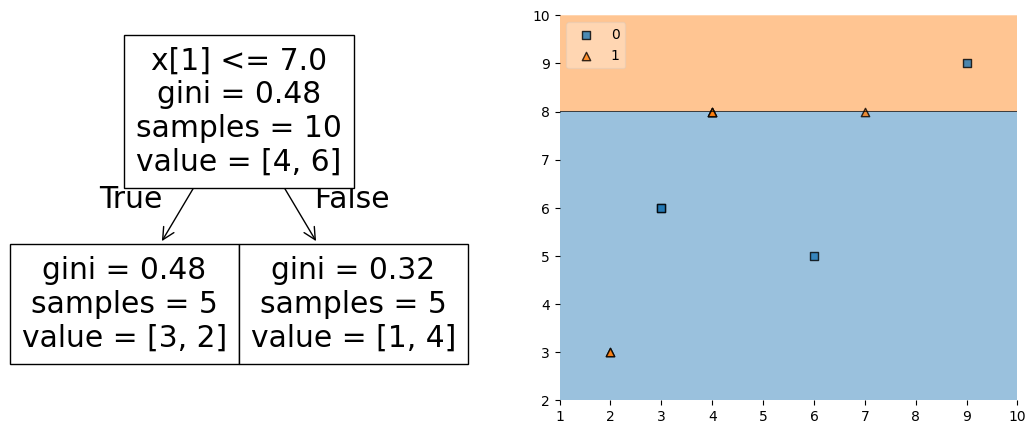

In [139]:
dt3 = DecisionTreeClassifier(max_depth=1)

X = second_df.iloc[:,:2].values
y = second_df['label'].values

dt3.fit(X,y)
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
print(plot_tree(dt3))

plt.subplot(1,2,2)
plot_decision_regions(X,y,clf=dt3,legend=2)
df3['y_pred'] = dt3.predict(X)
print(df3)

In [140]:
alpha = claculate_model_weight(0.5)
alpha3 = alpha

In [141]:
print(alpha1,alpha2,alpha3)

0.4236489301934352 0.4236489301934352 -1.0003109451873661e-13


In [147]:
dt1.predict(np.array([1,5]).reshape(1,2))

array([1])

In [148]:
dt2.predict(np.array([1,5]).reshape(1,2))

array([0])

In [149]:
dt3.predict(np.array([1,5]).reshape(1,2))

array([0])

In [160]:
alpha1+alpha2*(-1)+alpha3*(-1)

np.float64(1.0003109451873661e-13)

In [161]:
np.sign(1.0003109451873661e-13)

np.float64(1.0)

In [162]:
dt1.predict(np.array([9,9]).reshape(1,2))

array([0])

In [163]:
dt2.predict(np.array([9,9]).reshape(1,2))

array([1])

In [164]:
dt3.predict(np.array([9,9]).reshape(1,2))

array([1])

In [165]:
alpha1*(-1) + alpha2*1+alpha3*1

np.float64(-1.0003109451873661e-13)

In [166]:
np.sign(-1.0003109451873661e-13)

np.float64(-1.0)